In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/Sample - Superstore.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/Sample - Superstore.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Download Sample - Superstore.csv and place it in the project's data folder."
    )

df = pd.read_csv(DATA_PATH, encoding="latin1")
print("Dataset loaded successfully.")
print("Shape (rows, columns):", df.shape)
display(df.head())

Dataset loaded successfully.
Shape (rows, columns): (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Understand the data

In [2]:
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
print("\\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0
\nMissing values by column:


,missing_count
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


## 2. Basic data preparation

In [3]:
# Convert dates where these columns are available
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Ensure numeric columns are numeric
for col in ["Sales", "Profit", "Quantity", "Discount"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Avoid silently deleting data. Report missingness first; use analysis-specific subsets below.
print("Rows before cleaning:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Rows after removing exact duplicate rows:", len(df))

if "Order Date" in df.columns:
    df["Order Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
if {"Sales", "Profit"}.issubset(df.columns):
    df["Profit Margin"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"], np.nan)
display(df.head())

Rows before cleaning: 9994
Exact duplicate rows: 0
Rows after removing exact duplicate rows: 9994


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Month,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016-11-01,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016-11-01,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016-06-01,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015-10-01,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015-10-01,0.1125


## 3. Visualization 1 — Distribution of sales

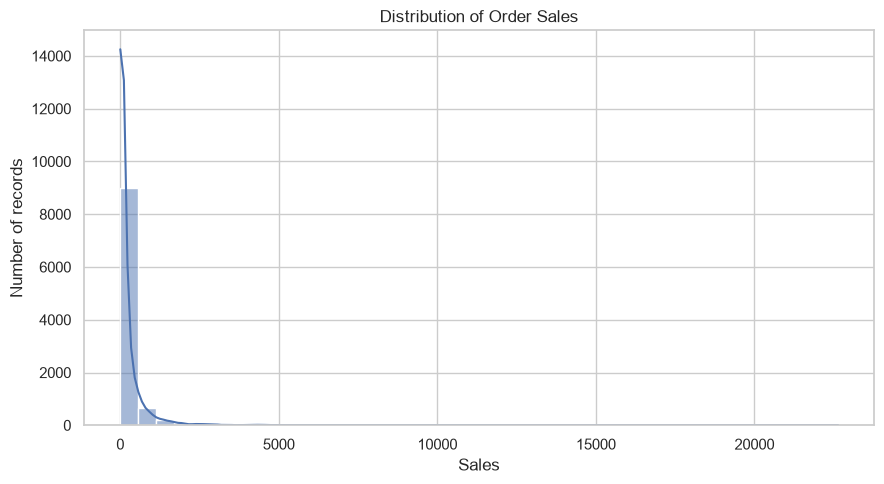

Observation: Sales range from 0.44 to 22638.48; median sales are 54.49. The shape shows whether most orders are small with a few large orders.


In [4]:
if "Sales" in df.columns:
    sales = df["Sales"].dropna()
    plt.figure(figsize=(9, 5))
    sns.histplot(sales, bins=40, kde=True)
    plt.title("Distribution of Order Sales")
    plt.xlabel("Sales")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()
    print(f"Observation: Sales range from {sales.min():.2f} to {sales.max():.2f}; median sales are {sales.median():.2f}. The shape shows whether most orders are small with a few large orders.")
else:
    print("Skipped: Sales column not found.")

## 4. Visualization 2 — Profit by product category

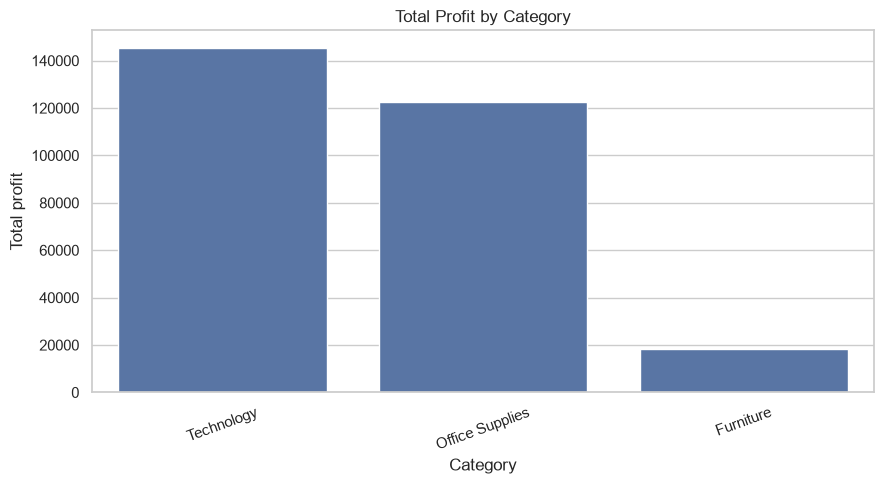

Observation: Compare the bars to identify the categories contributing the most and least total profit.


,total_profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


In [5]:
if {"Category", "Profit"}.issubset(df.columns):
    category_profit = df.groupby("Category", dropna=False)["Profit"].sum().sort_values(ascending=False)
    plt.figure(figsize=(9, 5))
    sns.barplot(x=category_profit.index.astype(str), y=category_profit.values)
    plt.title("Total Profit by Category")
    plt.xlabel("Category")
    plt.ylabel("Total profit")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    print("Observation: Compare the bars to identify the categories contributing the most and least total profit.")
    display(category_profit.to_frame("total_profit"))
else:
    print("Skipped: Category or Profit column not found.")

## 5. Visualization 3 — Monthly sales trend

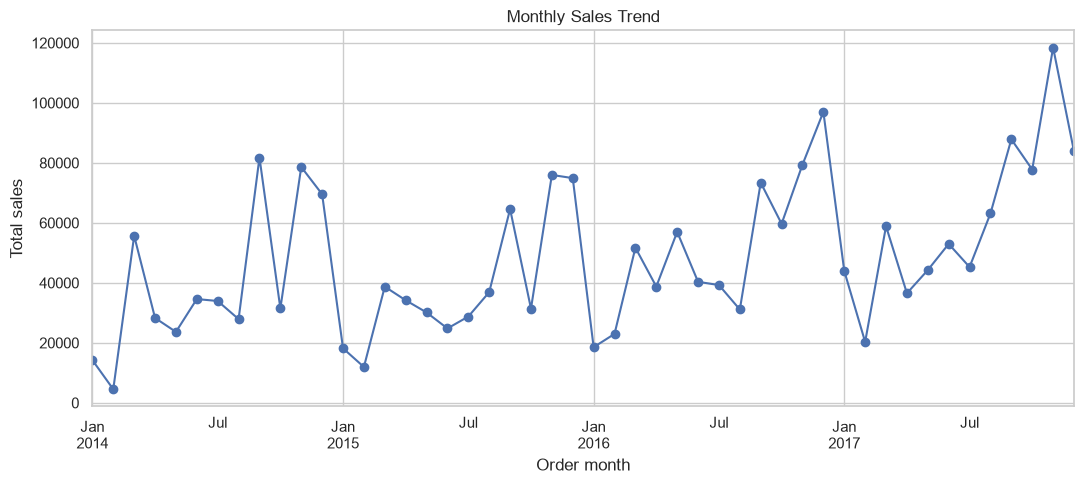

Observation: Highest-sales month is 2017-11 (118447.82); lowest-sales month is 2014-02 (4519.89).


In [6]:
if {"Order Month", "Sales"}.issubset(df.columns):
    monthly_sales = df.dropna(subset=["Order Month", "Sales"]).groupby("Order Month")["Sales"].sum()
    plt.figure(figsize=(11, 5))
    monthly_sales.plot(marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Order month")
    plt.ylabel("Total sales")
    plt.tight_layout()
    plt.show()
    if len(monthly_sales):
        print(f"Observation: Highest-sales month is {monthly_sales.idxmax():%Y-%m} ({monthly_sales.max():.2f}); lowest-sales month is {monthly_sales.idxmin():%Y-%m} ({monthly_sales.min():.2f}).")
else:
    print("Skipped: Order Date or Sales column not found.")

## 6. Visualization 4 — Outliers in sales and profit (boxplots)

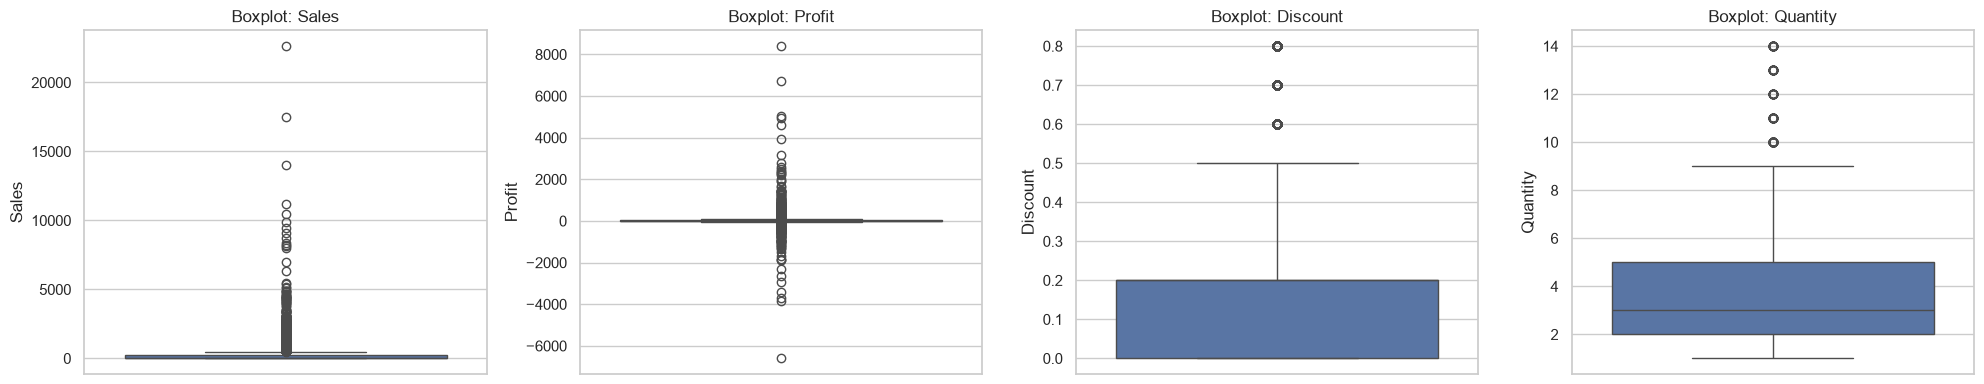

Sales: 1167 IQR-flagged values; lower=-271.71, upper=498.93
Profit: 1881 IQR-flagged values; lower=-39.72, upper=70.82
Discount: 856 IQR-flagged values; lower=-0.30, upper=0.50
Quantity: 170 IQR-flagged values; lower=-2.50, upper=9.50
Observation: Investigate flagged rows using source context. Do not remove outliers automatically; high-value orders can be genuine.


In [7]:
numeric_cols = [c for c in ["Sales", "Profit", "Discount", "Quantity"] if c in df.columns]
if numeric_cols:
    fig, axes = plt.subplots(1, len(numeric_cols), figsize=(5 * len(numeric_cols), 4))
    if len(numeric_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, numeric_cols):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(f"Boxplot: {col}")
    plt.tight_layout()
    plt.show()

    # IQR flag counts. A statistical flag is not proof of an error.
    for col in numeric_cols:
        values = df[col].dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = ((values < lower) | (values > upper)).sum()
        print(f"{col}: {flagged} IQR-flagged values; lower={lower:.2f}, upper={upper:.2f}")
    print("Observation: Investigate flagged rows using source context. Do not remove outliers automatically; high-value orders can be genuine.")
else:
    print("Skipped: no numeric columns available.")

## 7. Visualization 5 — Correlation heatmap

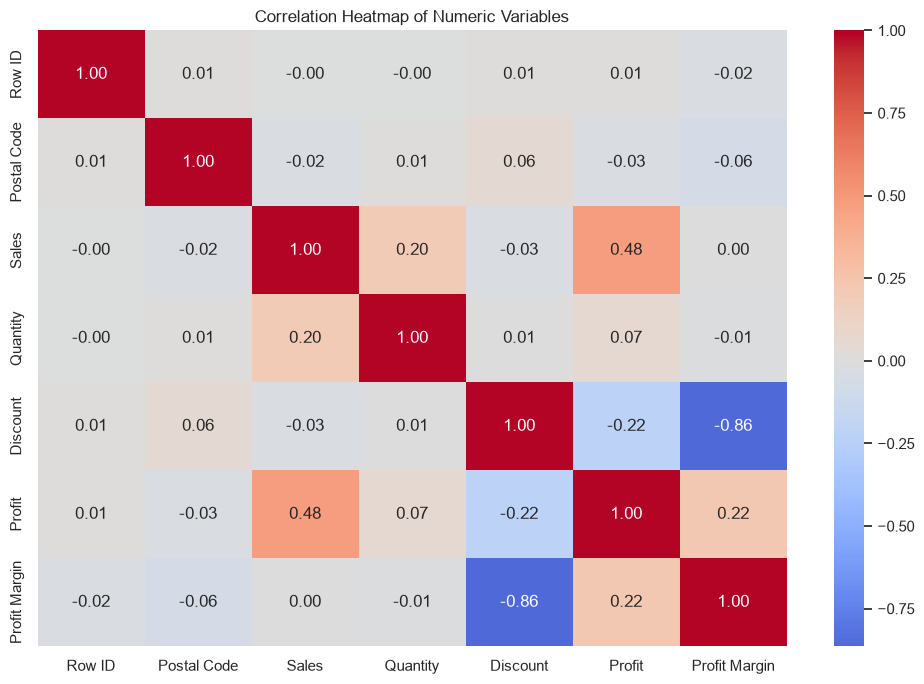

Observation: Correlation describes the strength and direction of linear association; it does not prove causation.


In [8]:
numeric_df = df.select_dtypes(include="number")
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap of Numeric Variables")
    plt.tight_layout()
    plt.show()
    print("Observation: Correlation describes the strength and direction of linear association; it does not prove causation.")
else:
    print("Skipped: fewer than two numeric columns.")

## 8. Visualization 6 — Discount versus profit

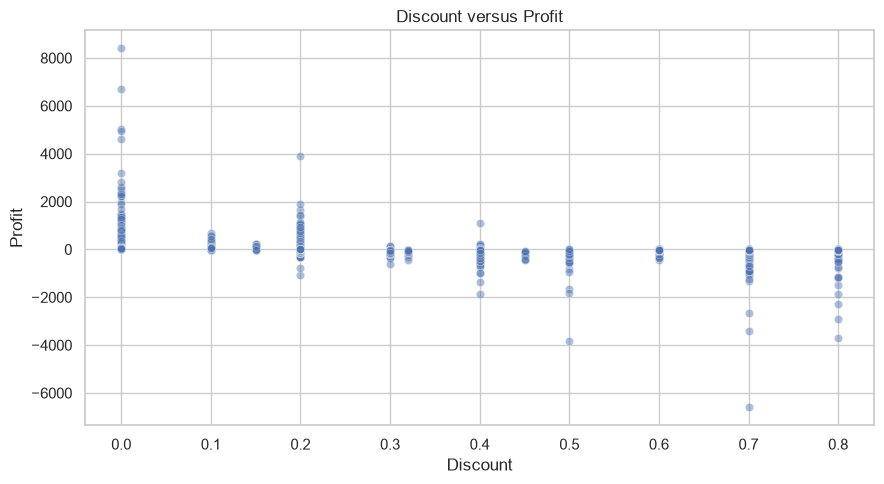

Pearson correlation: -0.219
Observation: Look for whether higher discounts tend to coincide with lower profit. This is an association, not proof that discount alone caused the profit outcome.


In [9]:
if {"Discount", "Profit"}.issubset(df.columns):
    sample = df[["Discount", "Profit"]].dropna()
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=sample, x="Discount", y="Profit", alpha=0.45)
    plt.title("Discount versus Profit")
    plt.xlabel("Discount")
    plt.ylabel("Profit")
    plt.tight_layout()
    plt.show()
    if len(sample) > 1:
        print("Pearson correlation:", round(sample["Discount"].corr(sample["Profit"]), 3))
    print("Observation: Look for whether higher discounts tend to coincide with lower profit. This is an association, not proof that discount alone caused the profit outcome.")
else:
    print("Skipped: Discount or Profit column not found.")

## 9. Top 3 insights

In [10]:
# These are data-driven prompts. Fill in the final statements after reviewing the tables and charts.
if {"Category", "Profit"}.issubset(df.columns):
    print("1. Category with highest total profit:", df.groupby("Category")["Profit"].sum().idxmax())
if {"Order Month", "Sales"}.issubset(df.columns):
    ms = df.dropna(subset=["Order Month", "Sales"]).groupby("Order Month")["Sales"].sum()
    if len(ms):
        print("2. Month with highest sales:", ms.idxmax().strftime("%Y-%m"))
if {"Discount", "Profit"}.issubset(df.columns):
    print("3. Discount-profit correlation:", round(df["Discount"].corr(df["Profit"]), 3))

1. Category with highest total profit: Technology
2. Month with highest sales: 2017-11
3. Discount-profit correlation: -0.219


## 10. Conclusion
Summarize the patterns actually observed in your charts. Mention data limitations, missing values, duplicate handling, and that correlation does not imply causation. Do not claim a finding unless your notebook output supports it.

## 11. Limitations
- The dataset is a sample retail dataset and may not represent all businesses.
- Outliers identified by the IQR rule require contextual review.
- Correlation shows association, not causation.